In [2]:
#Importing necessary libraries
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import scipy
import netCDF4
import pymannkendall as mk

In [ ]:
#to group the data into chillai kalan dictionary so I can retrieve it easily for plotting and analysis
ck = {}
for n in range(1981, 2026):

    dec1 = xr.open_dataset(f"raw data/Dec{n-1}.nc")
    jan1 = xr.open_dataset(f"raw data/Jan{n}.nc")

    dec = dec1.sel(valid_time=slice(f"{n-1}-12-21", f"{n-1}-12-31"))

    jan = jan1.sel(valid_time=slice(f"{n}-01-01", f"{n}-01-29"))

    ck[n] = xr.concat([dec, jan], dim="valid_time", join="exact")

print(ck)

In [3]:
# Check for problems in the data
problem_years = []

for n in range(1981, 2026):

    dec1 = xr.open_dataset(f"raw data/Dec{n-1}.nc")
    jan1 = xr.open_dataset(f"raw data/Jan{n}.nc")

    dec = dec1.sel(valid_time=slice(f"{n-1}-12-21", f"{n-1}-12-31"))
    jan = jan1.sel(valid_time=slice(f"{n}-01-01", f"{n}-01-29"))

    try:
        xr.concat([dec, jan], dim="valid_time", join="exact")

    except Exception as e:
        problem_years.append(n)
        print(f"\nProblem in Chillai Kalan {n}:")
        print(type(e).__name__)
        print(e)

print("\n--------------------------------")
print("Problem years:")
print(problem_years)


--------------------------------
Problem years:
[]


Threshold = -14.021184158325195 °C


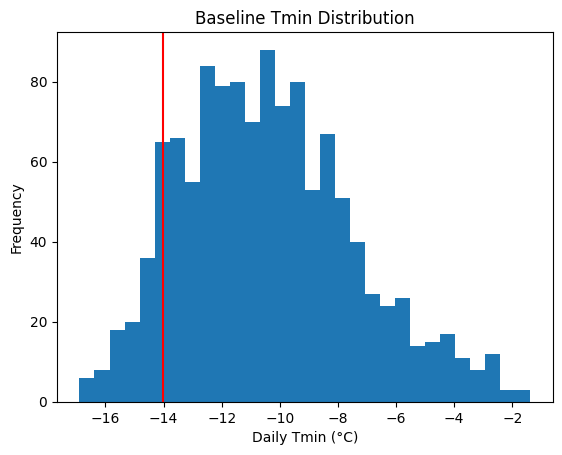

In [4]:
'''To store temp in celsius and calculate daily minimum temperature and then the mean of daily minimum for the entire 
region for all the years in our study (i.e. 1981-2025)'''
ck2 = {}
dmin = {}
mean_tmin = {}
for n in range(1981, 2026):
    ck2[n] = ck[n].t2m - 273.15
    ck2[n].attrs["units"] = "°C"
    dmin[n] = ck2[n].resample(valid_time="1D").min()
    mean_tmin[n] = dmin[n].mean(dim=["latitude", "longitude"])

#To calculate the 10th percentile of the mean daily minimum temperature for the baseline period (1991-2020)
baseline = xr.concat([mean_tmin[n] for n in range(1991, 2021)], dim="valid_time")
baseline.attrs["units"] = "°C"

threshold = baseline.quantile(0.10)
print("Threshold =", threshold.values, "°C")
plt.hist(baseline.values, bins=30)
plt.axvline(threshold, color='red')
plt.xlabel("Daily Tmin (°C)")
plt.ylabel("Frequency")
plt.title("Baseline Tmin Distribution")
plt.show()

In [7]:
#To count cold wave days from the 10th percentile method
cw_days = {}
for n in range(1981, 2026):
    cw_days[n] = (mean_tmin[n] < threshold).sum().values

Trend: no trend
p-value: 0.6488850373708477
Tau: -0.047474747474747475
Sen slope: 0.0


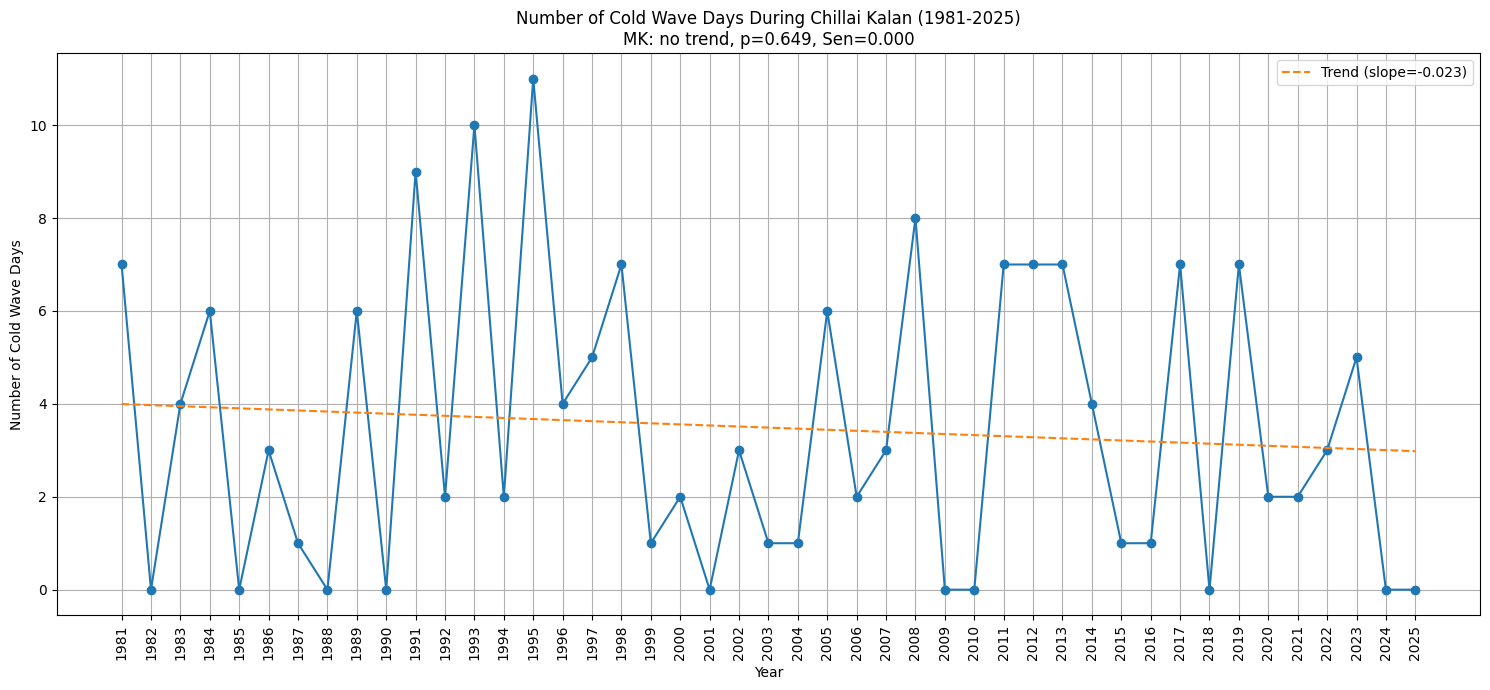

In [71]:
#Now the plotting part
years = np.array(list(cw_days.keys()))
cw_counts = np.array(list(cw_days.values()))

m, c = np.polyfit(years, cw_counts, 1)
trend = m*years + c

#To do Mann-Kendall test for trend analysis and get sen slope and p-value
result = mk.original_test(cw_counts)
print("Trend:", result.trend)
print("p-value:", result.p)
print("Tau:", result.Tau)
print("Sen slope:", result.slope)

plt.figure(figsize=(15,7))
plt.plot(years, cw_counts, marker='o', linestyle='-')
plt.plot(years, trend, '--', label=f"Trend (slope={m:.3f})")

plt.title(f"Number of Cold Wave Days During Chillai Kalan (1981-2025)\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
plt.xlabel("Year")
plt.ylabel("Number of Cold Wave Days")

plt.grid(True)
plt.xticks(years, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

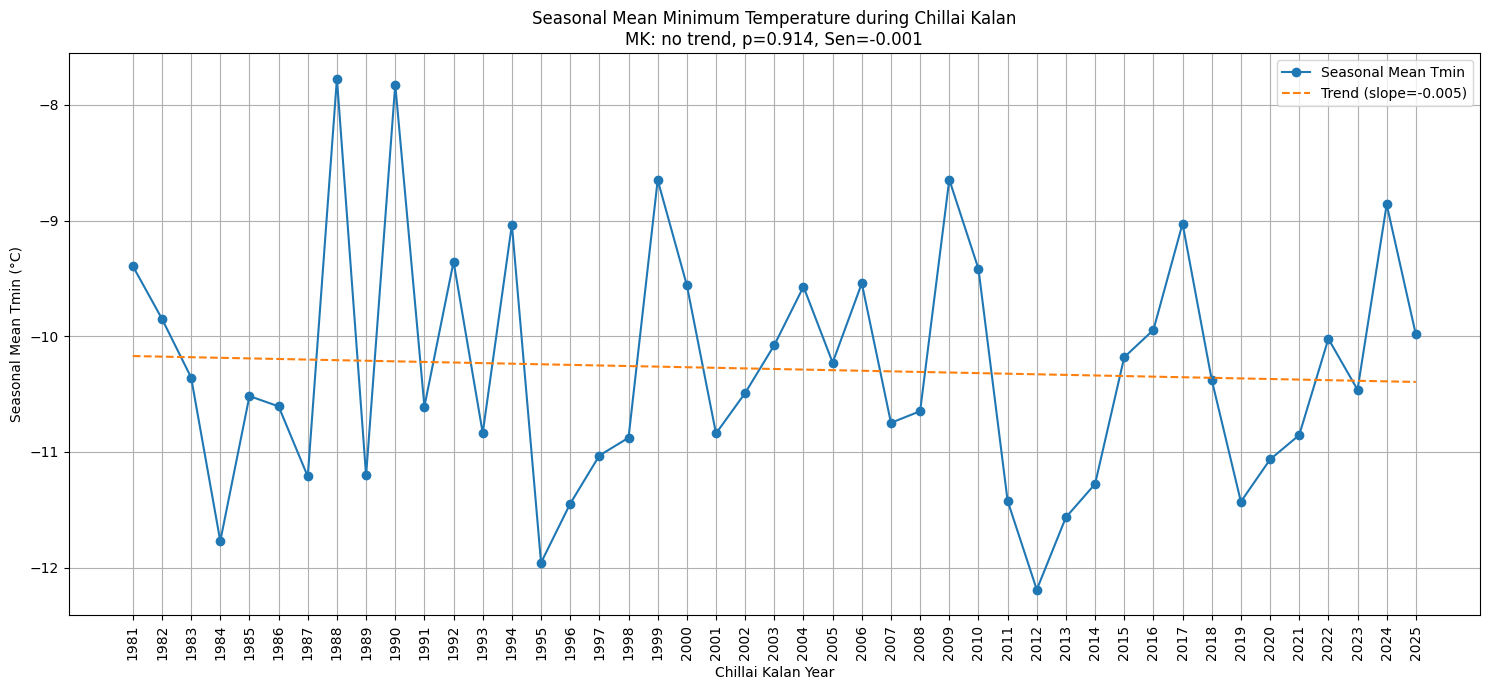

In [50]:
#To calculate mean seasonal minimum temperature for each year and then plot the time series of the same
seasonal_mean_tmin = {}
for n in range(1981, 2026):
    seasonal_mean_tmin[n] = mean_tmin[n].mean().values

temp_series = list(seasonal_mean_tmin.values())

m, c = np.polyfit(years, temp_series, 1)
trend = m*years + c
result = mk.original_test(temp_series)

plt.figure(figsize=(15,7))
plt.plot(years, temp_series, marker="o", linestyle="-", label="Seasonal Mean Tmin")
plt.plot(years, trend, '--', label=f"Trend (slope={m:.3f})")

plt.xlabel("Chillai Kalan Year")
plt.ylabel("Seasonal Mean Tmin (°C)")
plt.title("Seasonal Mean Minimum Temperature during Chillai Kalan")
plt.title(f"Seasonal Mean Minimum Temperature during Chillai Kalan\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
plt.grid(True)
plt.xticks(years, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
#Running Mann-Kendall test for trend analysis on the seasonal mean minimum temperature
result = mk.original_test(temp_series)

print("Trend:", result.trend)
print("p-value:", result.p)
print("Tau:", result.Tau)
print("Sen slope:", result.slope)

Trend: no trend
p-value: 0.914308620179539
Tau: -0.012121212121212121
Sen slope: -0.0008864546644276586


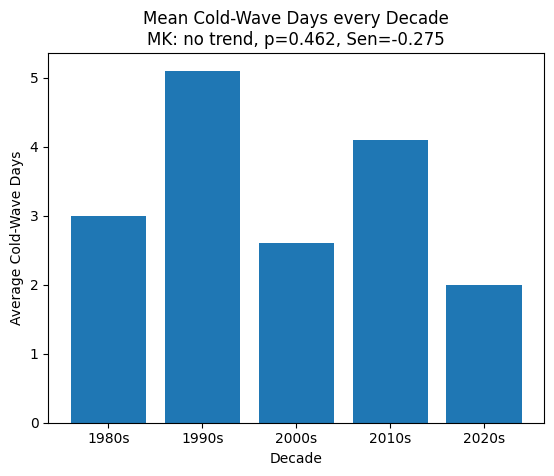

In [52]:
#Separating decades for better visualization of the trend and variability of cold wave days 
decades = {"1980s": [], "1990s": [], "2000s": [], "2010s": [], "2020s": []}

for year, value in cw_days.items():

    if year < 1990:
        decades["1980s"].append(value)

    elif year < 2000:
        decades["1990s"].append(value)

    elif year < 2010:
        decades["2000s"].append(value)

    elif year < 2020:
        decades["2010s"].append(value)

    else:
        decades["2020s"].append(value)

decadal_mean = {
    k: np.mean(v)
    for k, v in decades.items()
}

result = mk.original_test(list(decadal_mean.values()))

plt.bar(decadal_mean.keys(),decadal_mean.values())
plt.xlabel("Decade")
plt.ylabel("Average Cold-Wave Days")
plt.title("Decadal Mean Cold-Wave Days")
plt.title(f"Mean Cold-Wave Days every Decade\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
plt.show()

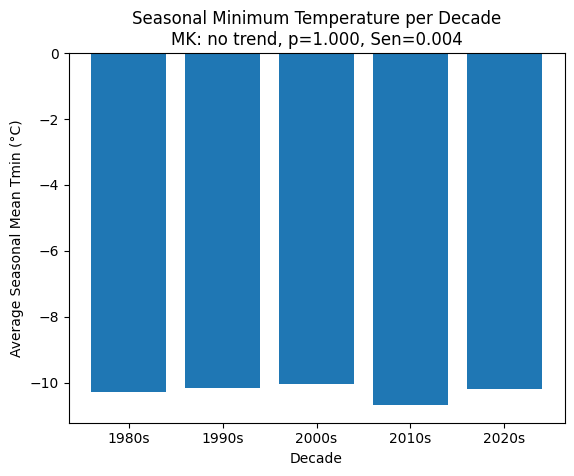

In [54]:
#Separating decades for better visualization of the trend and variability of mean seasonal minimum temperature
decade2 = {"1980s": [], "1990s": [], "2000s": [], "2010s": [], "2020s": []}

for year, value in seasonal_mean_tmin.items():

    if year < 1990:
        decade2["1980s"].append(value)

    elif year < 2000:
        decade2["1990s"].append(value)

    elif year < 2010:
        decade2["2000s"].append(value)

    elif year < 2020:
        decade2["2010s"].append(value)

    else:
        decade2["2020s"].append(value)
decadal_mean2 = { k : np.mean(v) for k, v in decade2.items() }
result = mk.original_test(list(decadal_mean2.values()))
plt.bar(decadal_mean2.keys(),decadal_mean2.values())
plt.xlabel("Decade")
plt.ylabel("Average Seasonal Mean Tmin (°C)")
plt.title(f"Seasonal Minimum Temperature per Decade\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")

plt.show()

In [14]:
#Now we will do the same for each and every grid point to see the spatial distribution of the trend
b_grid = xr.concat([dmin[n] for n in range(1991,2021)], dim="valid_time")
t_grid = b_grid.quantile(0.10, dim="valid_time")

cw_grid = []

for n in range(1981, 2026):

    cw = (dmin[n] < t_grid).sum(dim="valid_time") #separate variable included to calculate no of cw days for each grid point
    cw_grid.append(cw)

cw_grid = xr.concat(cw_grid, dim="year")
cw_grid["year"] = np.arange(1981, 2026) #to add year as a coordinate to the cw_grid dataset for easier retrieval and plotting

print(b_grid.shape)
print(t_grid.shape)
print(cw_grid.shape)
print(cw_grid.latitude.values[:5]) #to check the latitude values of the grid points increasing or decreasing
print(cw_grid.longitude.values[:5]) #to check the longitude values of the grid points increasing or decreasing

(1200, 39, 39)
(39, 39)
(45, 39, 39)
[35.8 35.7 35.6 35.5 35.4]
[73.  73.1 73.2 73.3 73.4]


In [ ]:
'''Truncating the grid data to specific regions'''

'''SRINAGAR'''
srinagar = cw_grid.sel(latitude=slice(34.2, 34.0), longitude=slice(74.7, 74.9))

'''GULMARG'''
gulmarg = cw_grid.sel(latitude=slice(34.1, 33.9), longitude=slice(74.3, 74.5))

'''PAHALGAM'''
pahalgam = cw_grid.sel(latitude=slice(34.1, 33.9), longitude=slice(75.2, 75.4))

'''BARAMULLA'''
baramulla = cw_grid.sel(latitude=slice(34.3, 34.1), longitude=slice(74.3, 74.5))

'''KUPWARA'''
kupwara = cw_grid.sel(latitude=slice(34.6, 34.4), longitude=slice(74.1, 74.3))

'''QUAZIGAND'''
qazigund = cw_grid.sel(latitude=slice(33.7, 33.5), longitude=slice(75.0, 75.2))

'''ISLAMABAD'''
islamabad = cw_grid.sel(latitude=slice(33.8, 33.6), longitude=slice(75.0, 75.2))

In [31]:
'''To calculate the mean number of cold wave days for each region and then plot the time series of the same'''
srinagar_cw = srinagar.mean(dim=["latitude", "longitude"])

gulmarg_cw = gulmarg.mean(dim=["latitude", "longitude"])

pahalgam_cw = pahalgam.mean(dim=["latitude", "longitude"])

islamabad_cw = islamabad.mean(dim=["latitude", "longitude"])

baramulla_cw = baramulla.mean(dim=["latitude", "longitude"])

kupwara_cw = kupwara.mean(dim=["latitude", "longitude"])

qazigund_cw = qazigund.mean(dim=["latitude", "longitude"])

In [ ]:
#Plotting the no of cold waves for each region
def plotting(series, name, color):

    years = series.year.values
    values = series.values

    # Linear regression
    m, c = np.polyfit(years, values, 1)
    trend = m*years + c

    # Mann-Kendall
    result = mk.original_test(values)

    plt.figure(figsize=(10,5))
    plt.plot(years,values,marker='o', label="Cold Wave Days", color=color)
    plt.plot(years, trend, '--', label=f"OLS slope={m:.3f}", color='black')

    plt.xlabel("Year")
    plt.xticks(years, rotation=90)
    plt.ylabel("Cold Wave Days")

    plt.title(f"{name}\n"
        f"MK: {result.trend}, "
        f"p={result.p:.3f}," f"Sen={result.slope:.3f}")

    plt.grid(True)
    plt.legend()
    plt.show()

    print(f"\n{name}")
    print("Trend      :", result.trend)
    print("p-value    :", result.p)
    print("Tau        :", result.Tau)
    print("Sen slope  :", result.slope)

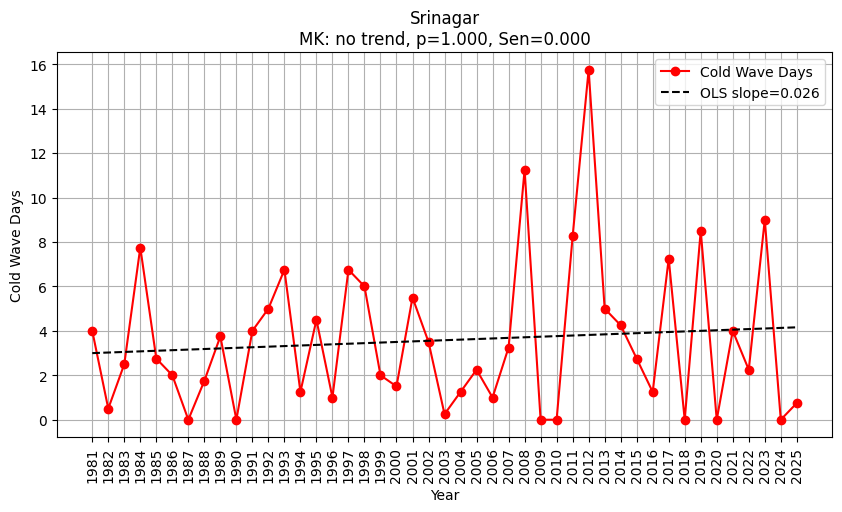


Srinagar
Trend      : no trend
p-value    : 1.0
Tau        : -0.00101010101010101
Sen slope  : 0.0


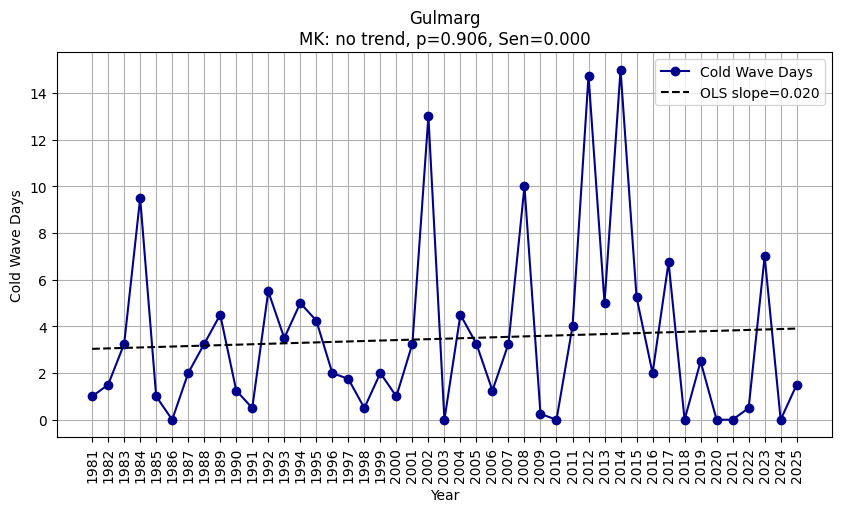


Gulmarg
Trend      : no trend
p-value    : 0.9061901187516006
Tau        : -0.013131313131313131
Sen slope  : 0.0


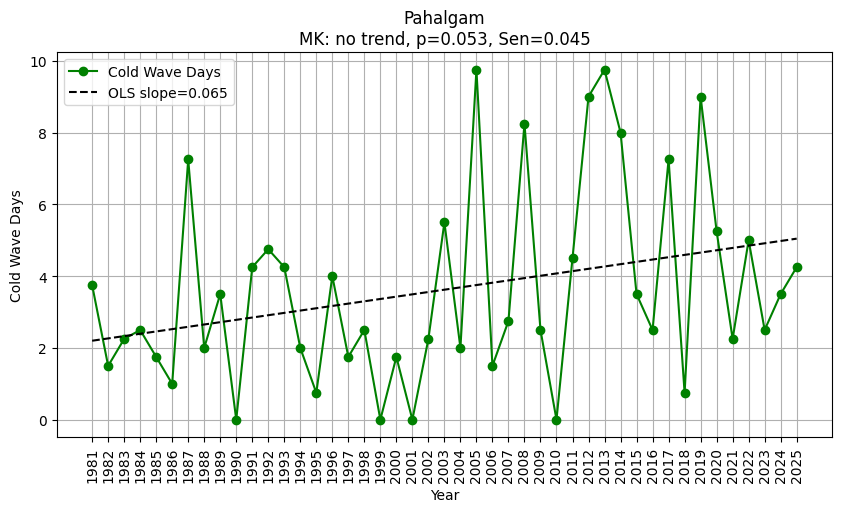


Pahalgam
Trend      : no trend
p-value    : 0.05340641146207492
Tau        : 0.2
Sen slope  : 0.045454545454545456


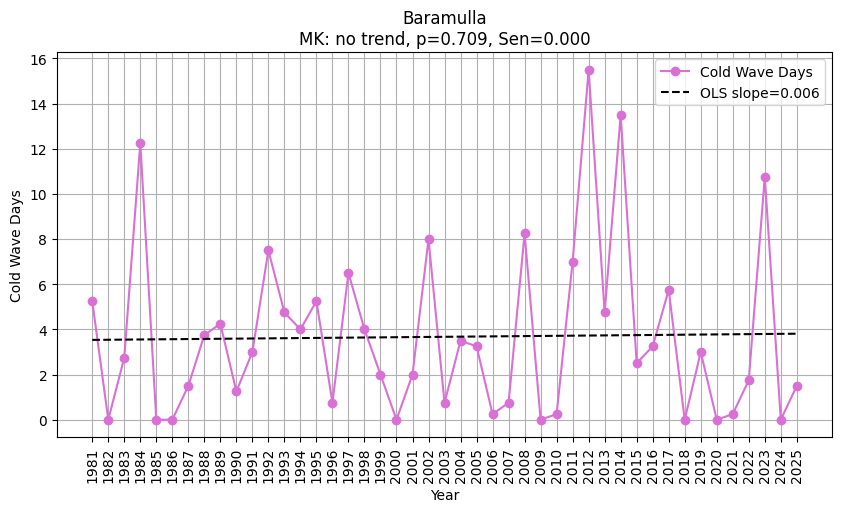


Baramulla
Trend      : no trend
p-value    : 0.7090343819129044
Tau        : -0.03939393939393939
Sen slope  : 0.0


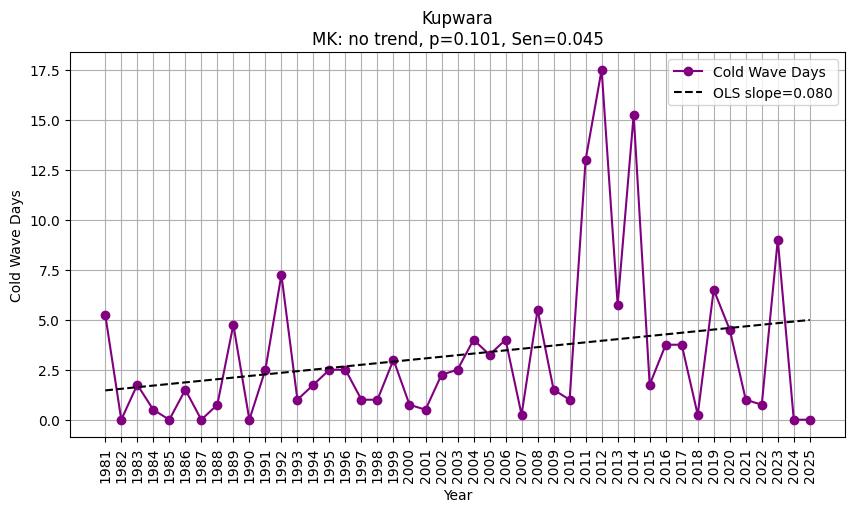


Kupwara
Trend      : no trend
p-value    : 0.10124849175012174
Tau        : 0.1696969696969697
Sen slope  : 0.04478609625668449


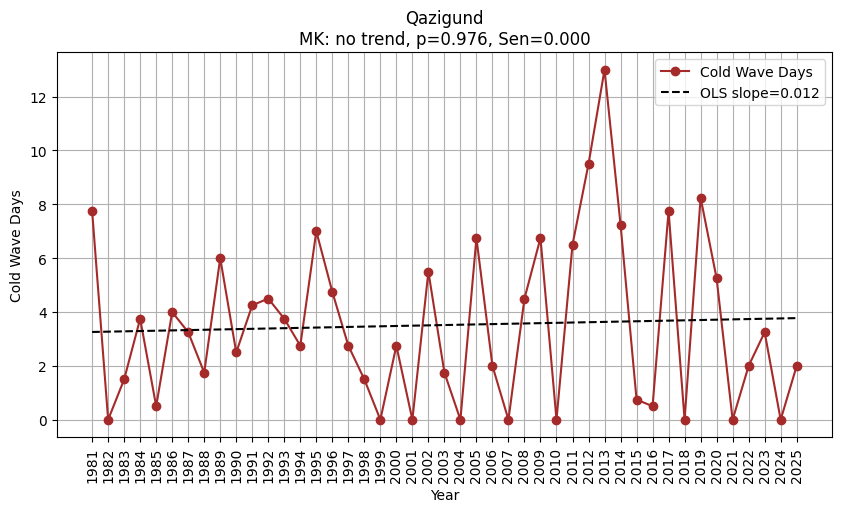


Qazigund
Trend      : no trend
p-value    : 0.9764667412478902
Tau        : 0.00404040404040404
Sen slope  : 0.0


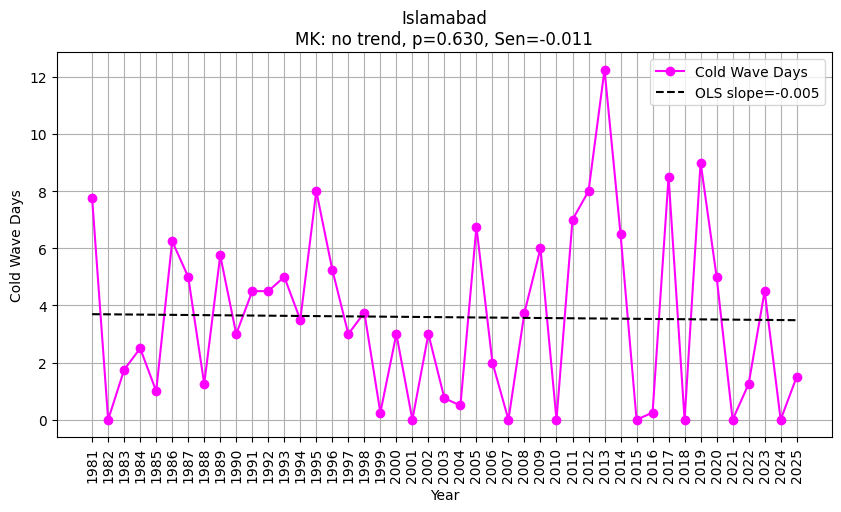


Islamabad
Trend      : no trend
p-value    : 0.6303012899538099
Tau        : -0.050505050505050504
Sen slope  : -0.010643115942028984


In [45]:
plotting(srinagar_cw, "Srinagar", "red")
plotting(gulmarg_cw, "Gulmarg", "darkblue")
plotting(pahalgam_cw,  "Pahalgam", "green")
plotting(baramulla_cw, "Baramulla", "orchid")
plotting(kupwara_cw,   "Kupwara", "purple")
plotting(qazigund_cw,  "Qazigund", "brown")
plotting(islamabad_cw,  "Islamabad", "magenta")

In [19]:
#To plot the minimum temperature for each region and then plot the time series of the same
srinagar_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(34.2,34), longitude=slice(74.7,74.9))
    srinagar_tmin.append(temp.mean().values)

gul_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(34.1,33.9), longitude=slice(74.3,74.5))
    gul_tmin.append(temp.mean().values)

pah_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(34.1,33.9), longitude=slice(75.2,75.4))
    pah_tmin.append(temp.mean().values)

qazi_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(33.7,33.5), longitude=slice(75,75.2))
    qazi_tmin.append(temp.mean().values)

kup_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(34.6,34.4), longitude=slice(74.1,74.3))
    kup_tmin.append(temp.mean().values)

bara_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(34.3,34.1), longitude=slice(74.3,74.5))
    bara_tmin.append(temp.mean().values)

padosi_tmin = []
for n in range(1981,2026):
    temp = dmin[n].sel(latitude=slice(33.8,33.6), longitude=slice(75,75.2))
    padosi_tmin.append(temp.mean().values)


In [46]:
#Now comes the plotting part for the minimum temperature time series for each region
import numpy as np
import matplotlib.pyplot as plt
import pymannkendall as mk

def plot_temp(region, name):

    years = np.array(range(1981, 2026))
    m, c = np.polyfit(years, region, 1)
    trend = m*years + c

    result = mk.original_test(region)

    plt.figure(figsize=(10,5))
    plt.plot(years, region, marker="o", label="Mean Daily Minimum Temperature", color='green')
    plt.plot(years, trend, '--', label=f"Trend (slope={m:.3f})")

    plt.xlabel("Year")
    plt.xticks(years, rotation=90)
    plt.ylabel("Mean Daily Minimum Temperature (°C)")
    plt.title(f"{name} - Seasonal Mean Minimum Temperature during Chillai Kalan")
    plt.title(f"{name}\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")

    plt.grid(True)
    plt.legend()
    plt.show()

    print(f"\n{name}")
    print("Trend      :", result.trend)
    print("p-value    :", result.p)
    print("Tau        :", result.Tau)
    print("Sen slope  :", result.slope)

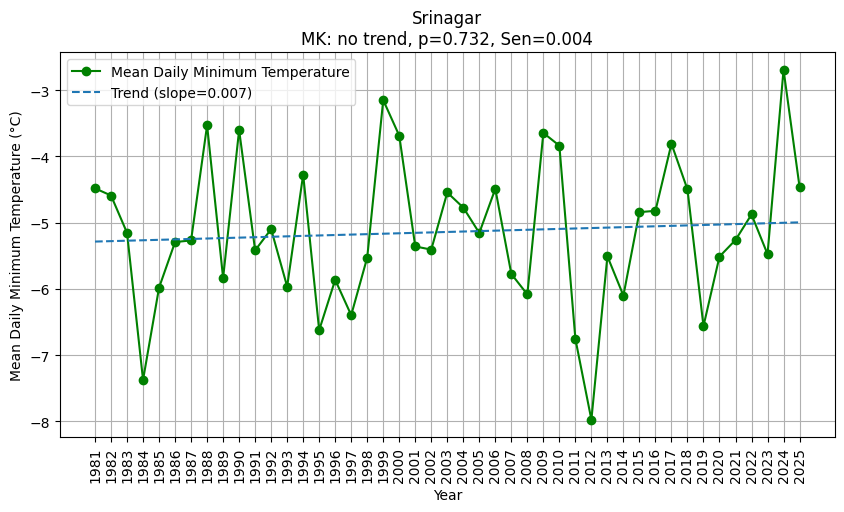


Srinagar
Trend      : no trend
p-value    : 0.7320640410462687
Tau        : 0.03636363636363636
Sen slope  : 0.004173010587692261


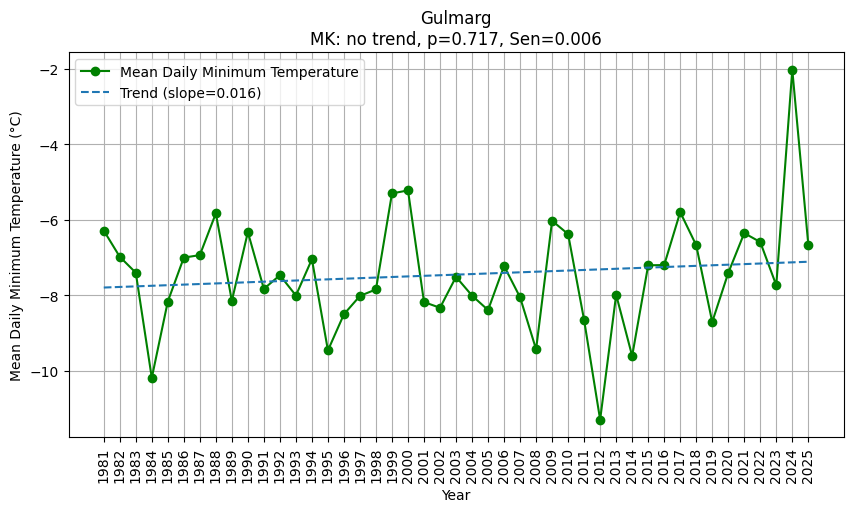


Gulmarg
Trend      : no trend
p-value    : 0.7173925102141454
Tau        : 0.03838383838383838
Sen slope  : 0.0062760607504741455


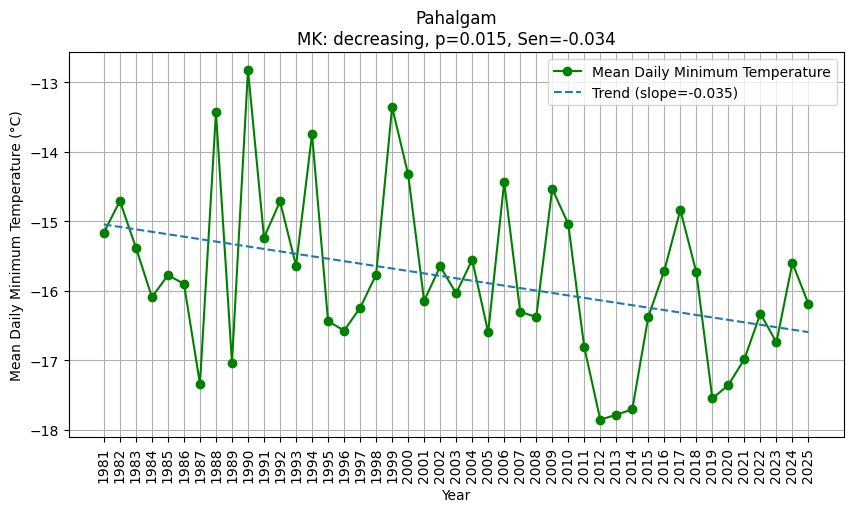


Pahalgam
Trend      : decreasing
p-value    : 0.014858995294660726
Tau        : -0.25252525252525254
Sen slope  : -0.03374460538228353


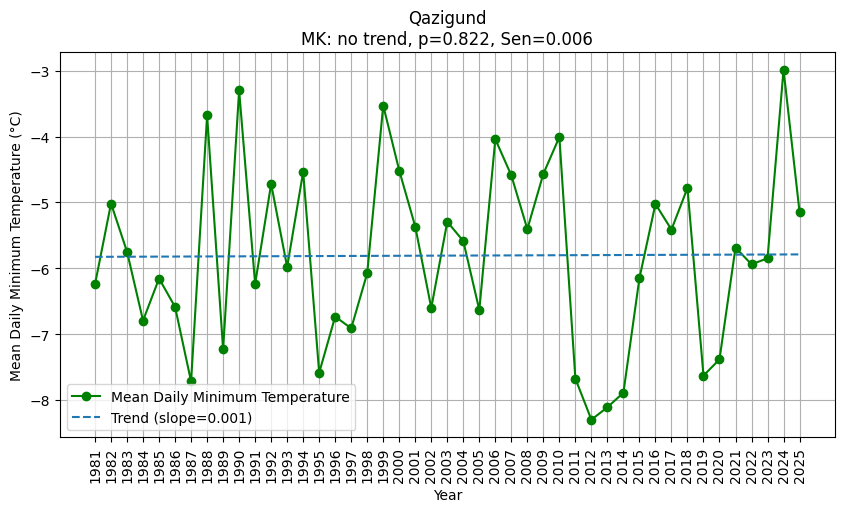


Qazigund
Trend      : no trend
p-value    : 0.8219844440767774
Tau        : 0.024242424242424242
Sen slope  : 0.005589544773101807


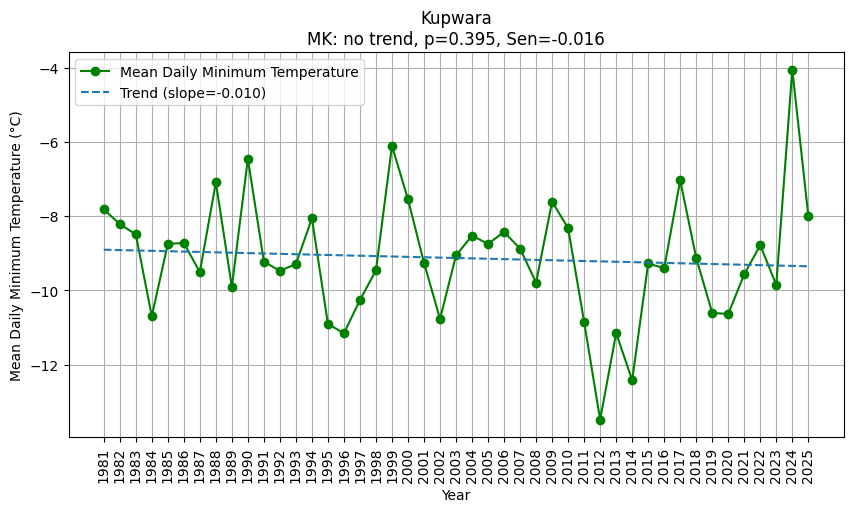


Kupwara
Trend      : no trend
p-value    : 0.3947350133030303
Tau        : -0.08888888888888889
Sen slope  : -0.01628167214600936


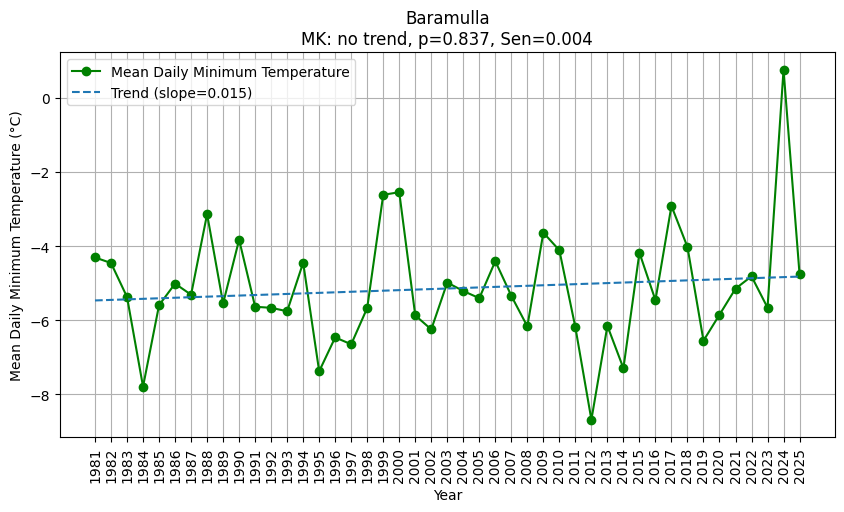


Baramulla
Trend      : no trend
p-value    : 0.8372371873444682
Tau        : 0.022222222222222223
Sen slope  : 0.0035701125275854973


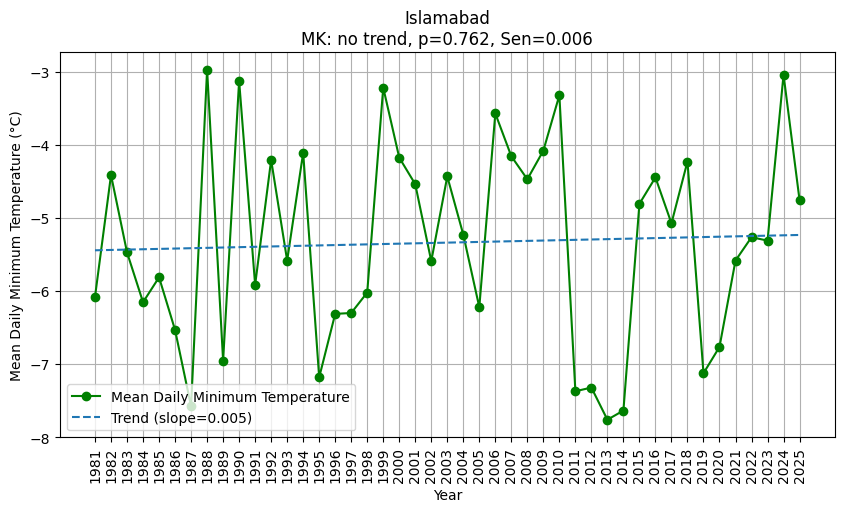


Islamabad
Trend      : no trend
p-value    : 0.7616978898670956
Tau        : 0.03232323232323232
Sen slope  : 0.006245797210269504


In [47]:
plot_temp(srinagar_tmin, "Srinagar")
plot_temp(gul_tmin, "Gulmarg")
plot_temp(pah_tmin, "Pahalgam")
plot_temp(qazi_tmin, "Qazigund")
plot_temp(kup_tmin, "Kupwara")
plot_temp(bara_tmin, "Baramulla")
plot_temp(padosi_tmin, "Islamabad")

In [22]:
#To find the correlation between the number of cold wave days and the mean seasonal minimum temperature for each region


In [3]:
#To store snowfall and precipitation data for each year
ds={}
sf={}
pt={}
sde={}

for n in range(1981, 2026):

    dec1 = xr.open_dataset(f"snow data/dec{n-1}.nc")
    jan1 = xr.open_dataset(f"snow data/jan{n}.nc")

    dec = dec1.sel(valid_time=slice(f"{n-1}-12-21", f"{n-1}-12-31"))
    jan = jan1.sel(valid_time=slice(f"{n}-01-01", f"{n}-01-29"))
    ds[n] = xr.concat([dec, jan], dim="valid_time", join="exact")

    sf[n] = ds[n].sf
    pt[n] = ds[n].tp
    sde[n] = ds[n].sde

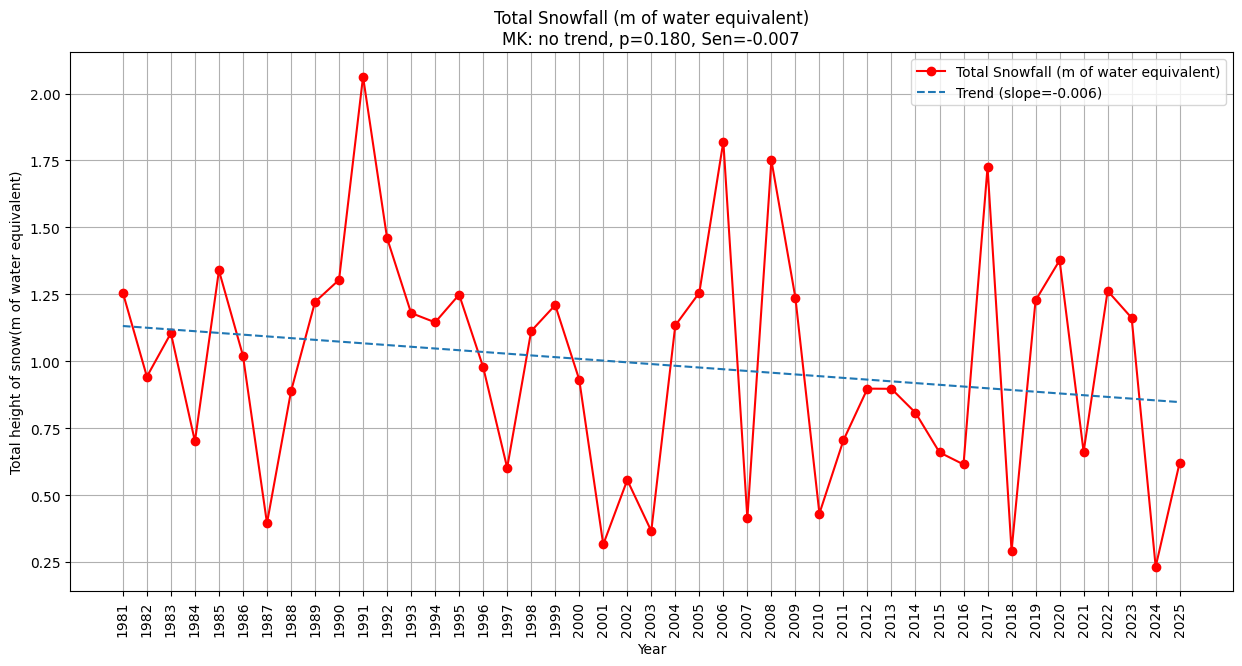

Mann-Kendall test result for Total Snowfall (m of water equivalent):
Trend: no trend
p-value: 0.18018754488317246
Tau: -0.1393939393939394
Sen slope: -0.007161207267978096


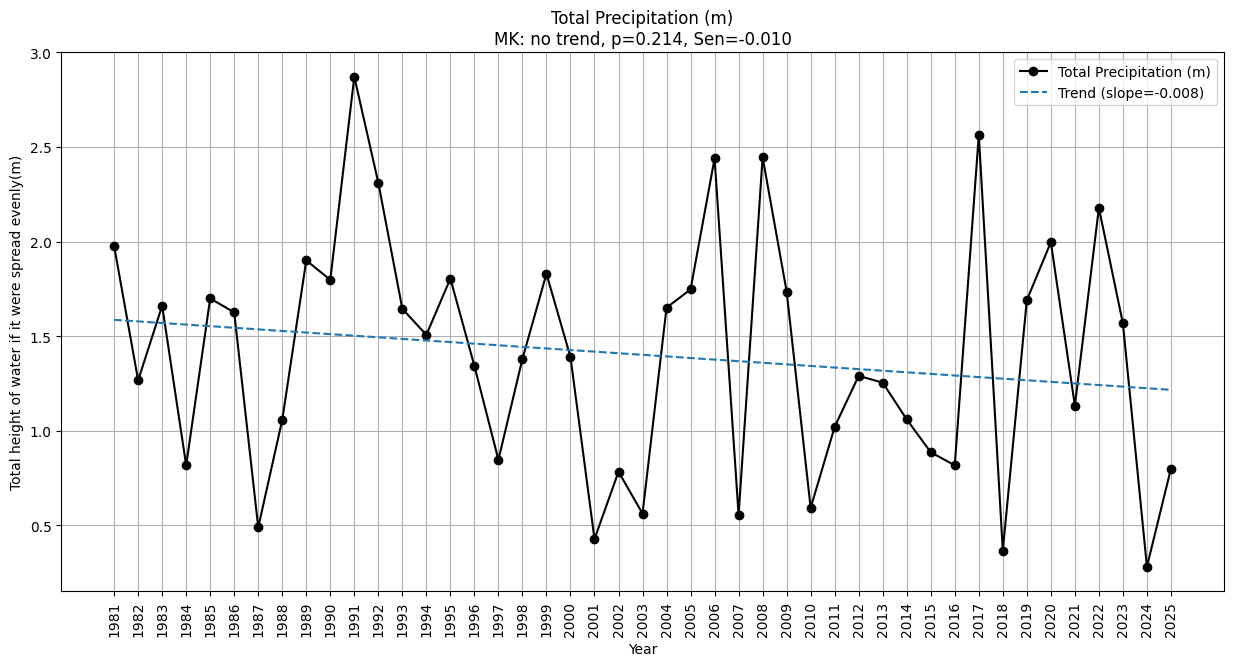

Mann-Kendall test result for Total Precipitation (m):
Trend: no trend
p-value: 0.2141057549143488
Tau: -0.1292929292929293
Sen slope: -0.01049018626684671


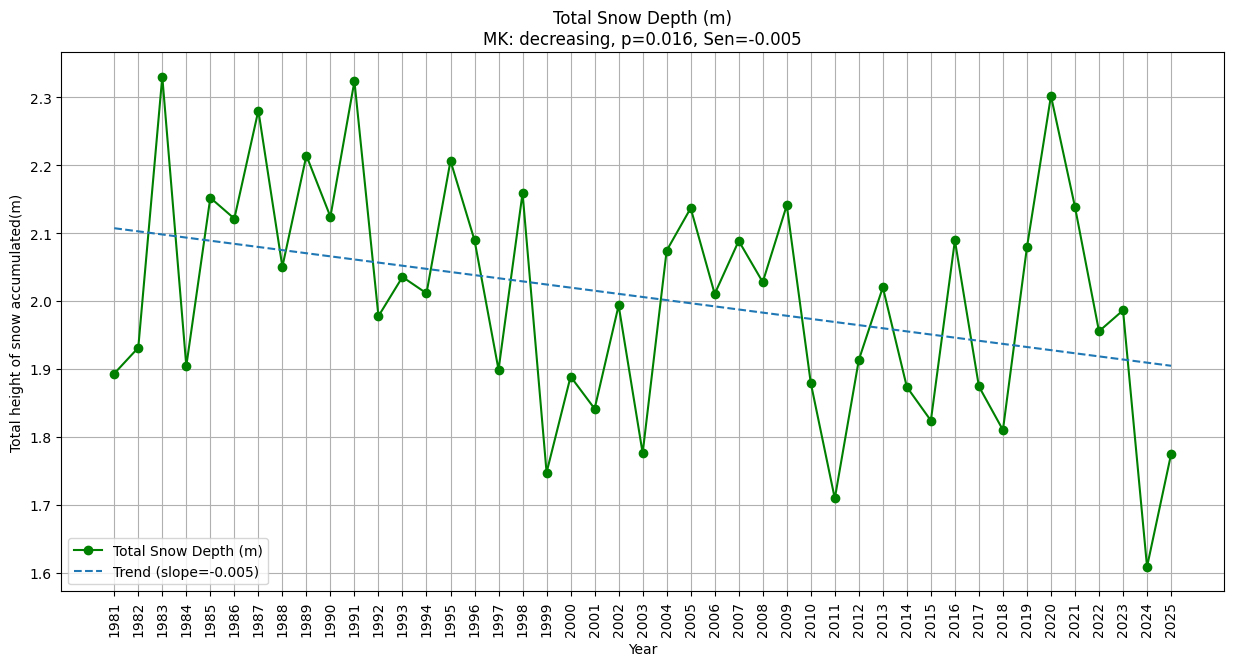

Mann-Kendall test result for Total Snow Depth (m):
Trend: decreasing
p-value: 0.01568202356807058
Tau: -0.2505050505050505
Sen slope: -0.004666225304679265


In [4]:
#To calucate the total snowfall, precipitation and snow depth for each year

sf_tot = {}
pt_tot = {}
sde_tot = {}
for n in range(1981, 2026):
    sf_tot[n] = (sf[n].sum(dim="valid_time").mean(dim=["latitude","longitude"]).values)
    pt_tot[n] = (pt[n].sum(dim="valid_time").mean(dim=["latitude","longitude"]).values)
    sde_tot[n] = (sde[n].mean(dim="valid_time").mean(dim=["latitude","longitude"]).values)

'''Plotting the time series of total snowfall, precipitation and snow depth for each year'''
def plot_trend(variable, title, ylabel, color):
    years = list(variable.keys())
    values = list(variable.values())
    m, b = np.polyfit(years, values, 1)
    trend = m * np.array(years) + b

    result = mk.original_test(values)
    
    plt.figure(figsize=(15,7))
    plt.plot(years, values, marker="o", label=title, color=color)
    plt.plot(years, trend, '--', label=f"Trend (slope={m:.3f})")
    plt.xlabel("Year")
    plt.ylabel(ylabel)
    plt.title(f"{title}\n"f"MK: {result.trend}, "f"p={result.p:.3f}, "f"Sen={result.slope:.3f}")
    plt.xticks(years, rotation=90)
    plt.grid(True)
    plt.legend()
    plt.show()

    print(f"Mann-Kendall test result for {title}:")
    print("Trend:", result.trend)
    print("p-value:", result.p)
    print("Tau:", result.Tau)
    print("Sen slope:", result.slope)

plot_trend(sf_tot, "Total Snowfall (m of water equivalent)", "Total height of snow(m of water equivalent)", 'red')
plot_trend(pt_tot, "Total Precipitation (m)", "Total height of water if it were spread evenly(m)", 'black')
plot_trend(sde_tot, "Total Snow Depth (m)", "Total height of snow accumulated(m)", 'green')

In [64]:
#To calculate mean climatology in snowfall, precipitation and snow depth for the baseline period (1991-2020)
baseline_years = range(1991, 2021)

sf_clim = np.mean([sf_tot[n] for n in baseline_years])
pt_clim = np.mean([pt_tot[n] for n in baseline_years])
sde_clim = np.mean([sde_tot[n] for n in baseline_years])
print("Mean climatology Snowfall (1991-2020):", sf_clim, "m of water equivalent")
print("Mean climatology Precipitation (1991-2020):", pt_clim, "m")
print("Mean climatology Snow Depth (1991-2020):", sde_clim, "m")

#Calculating the anomalies for snowfall and precipitation for each year
sf_anom = {}
pt_anom = {}
sde_anom = {}

for n in range(1981, 2026):

    sf_anom[n] = sf_tot[n] - sf_clim
    pt_anom[n] = pt_tot[n] - pt_clim
    sde_anom[n] = sde_tot[n] - sde_clim

Mean climatology Snowfall (1991-2020): 1.0138502 m of water equivalent
Mean climatology Precipitation (1991-2020): 1.4268608 m
Mean climatology Snow Depth (1991-2020): 1.9934068 m


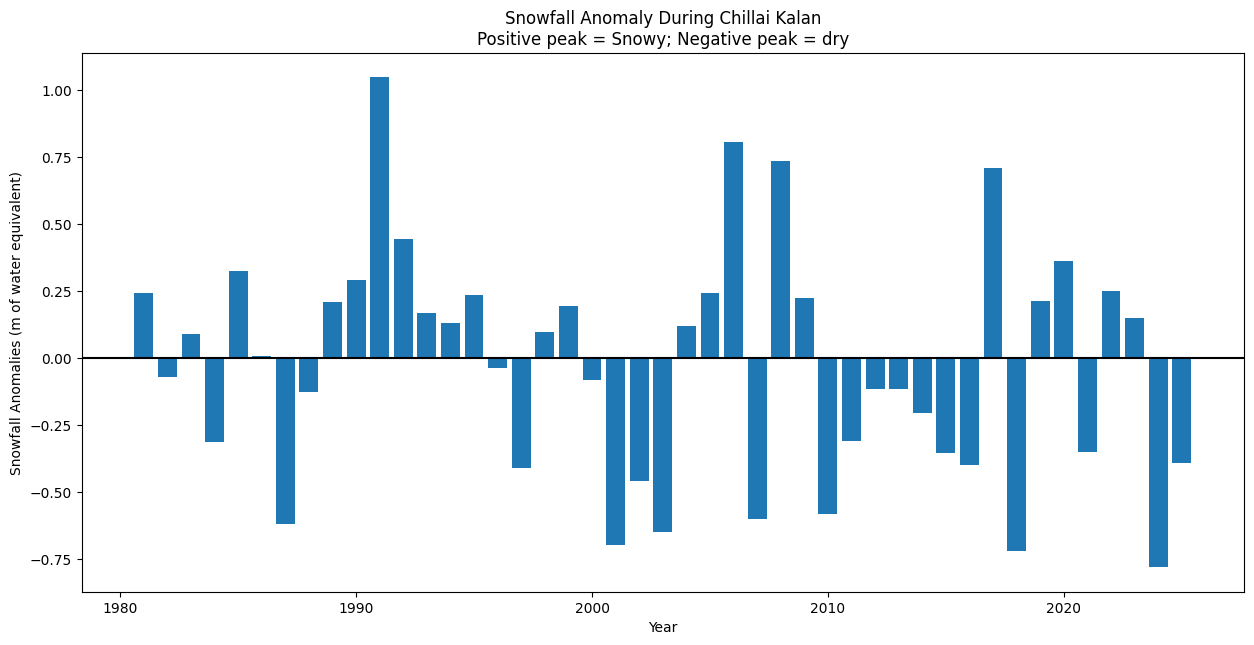

In [72]:
years = list(sf_anom.keys())
values = list(sf_anom.values())

plt.figure(figsize=(15,7))
plt.bar(years, values)
plt.axhline(0, color='black')

plt.title("Snowfall Anomaly During Chillai Kalan\nPositive peak = Snowy; Negative peak = dry")
plt.ylabel("Snowfall Anomalies (m of water equivalent)")
plt.xlabel("Year")
plt.show()

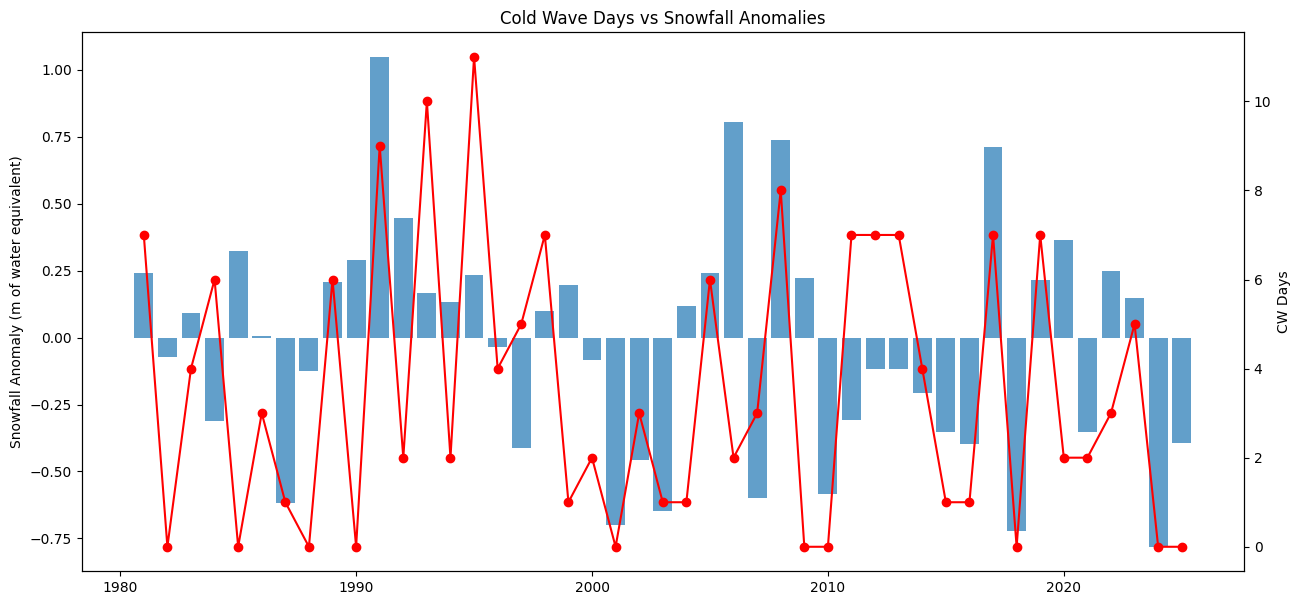

In [76]:
years = list(cw_days.keys())
cw = list(cw_days.values())
snow = list(sf_anom.values())
fig, ax1 = plt.subplots(figsize=(15,7))
ax1.bar(years, snow, alpha=0.7)
ax1.set_ylabel("Snowfall Anomaly (m of water equivalent)")
ax2 = ax1.twinx()
ax2.plot(years, cw,'ro-')
ax2.set_ylabel("CW Days")
plt.title("Cold Wave Days vs Snowfall Anomalies")
plt.show()

In [65]:
from scipy.stats import pearsonr

r, p = pearsonr(list(cw_days.values()), list(sf_anom.values()))
print("Correlation =", r)
print("p-value =", p)

Correlation = 0.43540075504929215
p-value = 0.0027964329860746717
